# HW5: 주문 데이터 전처리와 분석

sales_data.csv를 정리한 뒤 배송 기간, 만족도별 반품 비율, 카테고리별 매출을 살펴봤다.

### 준비

pandas와 matplotlib을 불러오고 한글 글꼴을 설정한다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

## 단계 1~4: 전처리

### 1. 데이터 읽기

원본 파일을 읽고 주문일, 배송일, 도착일을 날짜형으로 바꾼다.

In [2]:
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

### 결측치 확인

나이 51건, 만족도 30건, 도착일 5건이 비어 있다. 임의로 값을 채우지 않고 그대로 두고, 각 분석에 필요한 값이 없는 행은 계산에서 제외한다.

In [3]:
df.isnull().sum()[lambda s: s > 0]

delivery_date     5
customer_age     51
satisfaction     30
dtype: int64

### 2. 중복 제거

모든 칸이 같은 중복 행 26개를 제거했다. 행 수는 1,030개에서 1,004개로 줄었다.

In [4]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


### 3. 수량 복원

수량이 100개를 넘는 22건은 금액과 수량 × 단가가 맞지 않는다. 금액을 단가로 나누면 정수가 나오므로, 수업에서 정한 기준에 따라 수량을 이 값으로 복원했다.

In [5]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


### 4. 날짜 오류 표시와 저장

도착일이 배송일보다 빠른 147건은 어느 날짜가 잘못됐는지 알 수 없어 date_error로 표시했다. 원본을 덮어쓰지 않고 sales_clean.csv로 저장했다.

In [6]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].sum(), "건")

df.to_csv("sales_clean.csv", index=False)
df.shape

147 건


(1004, 15)

## 단계 5~7: 분석

### 5. 배송 기간은 보통 며칠인가?

도착일이 배송일보다 빠른 행을 제외하고 배송 기간을 계산했다. 도착일이 없는 5건도 계산에서 빠진다.

줄 수 : 852  평균 : 22.05  중앙값 : 2.0


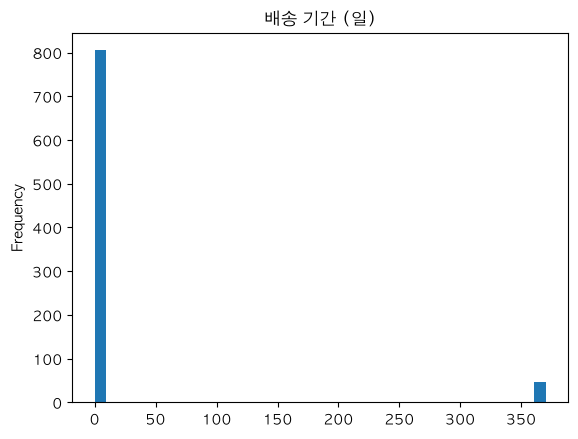

In [7]:
ok = df[~df["date_error"]]
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days

print("줄 수 :", days.count(), " 평균 :", round(days.mean(), 2), " 중앙값 :", days.median())

days.plot.hist(bins=40, title="배송 기간 (일)")
plt.show()

평균은 22.05일인데 중앙값은 2일이다. 히스토그램 오른쪽에 따로 떨어진 값들이 있어, 300일을 넘는 주문을 확인했다.

In [8]:
lump = days[days > 300]
print("덩어리 줄 수 :", len(lump), " 범위 :", lump.min(), "~", lump.max(), "일")

ok.loc[lump.index, ["order_date", "shipping_date", "delivery_date", "status"]].head(10)

덩어리 줄 수 : 47  범위 : 364.0 ~ 370.0 일


,order_date,shipping_date,delivery_date,status
11,2023-01-12,2023-01-15,2024-01-15,배송완료
20,2023-01-21,2023-01-23,2024-01-27,배송완료
29,2023-01-30,2023-02-03,2024-02-03,배송완료
41,2023-02-11,2023-02-14,2024-02-17,배송완료
68,2023-03-10,2023-03-14,2024-03-12,배송완료
99,2023-04-10,2023-04-11,2024-04-12,배송완료
110,2023-04-21,2023-04-25,2024-04-24,배송완료
131,2023-05-12,2023-05-13,2024-05-16,배송완료
165,2023-06-15,2023-06-16,2024-06-18,배송완료
192,2023-07-12,2023-07-13,2024-07-14,배송중


대부분은 0~5일이고, 47건은 364~370일에 모여 있다. 그 사이에 값이 없어 300일을 경계로 나눴다.

도착일 연도를 잘못 입력했을 가능성은 있지만, 1년을 빼면 7건은 배송 기간이 음수가 된다. 정확한 날짜를 알 수 없어 원본은 두고 배송 기간 분석에서만 제외했다.

제외한 줄 : 47  남은 줄 : 805
처리 후  평균 : 1.93  중앙값 : 2.0


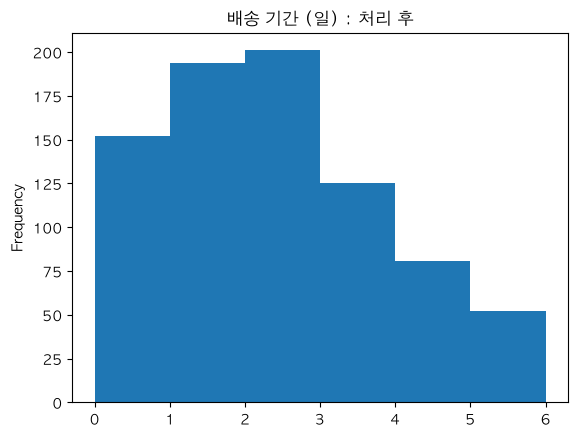

In [9]:
# 300일 초과 덩어리 47줄은 배송 기간 분석에서만 제외 (df 는 그대로)
days_fixed = days[days <= 300].copy()

print("제외한 줄 :", days.count() - days_fixed.count(), " 남은 줄 :", days_fixed.count())
print("처리 후  평균 :", round(days_fixed.mean(), 2), " 중앙값 :", days_fixed.median())
days_fixed.plot.hist(bins=range(0, int(days_fixed.max()) + 2), title="배송 기간 (일) : 처리 후")
plt.show()

364~370일인 47건 때문에 평균이 22.05일로 높아졌다. 중앙값은 2일이라 두 값의 차이가 컸다.
이 47건을 제외한 805건의 평균은 1.93일, 중앙값은 2일로, 이 주문들의 배송 기간은 보통 2일 정도다.

### 6. 만족도가 낮을수록 반품이 많은가?

만족도별로 전체 주문 중 반품 비율을 비교했다. 만족도가 없는 30건은 제외했다.

satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64


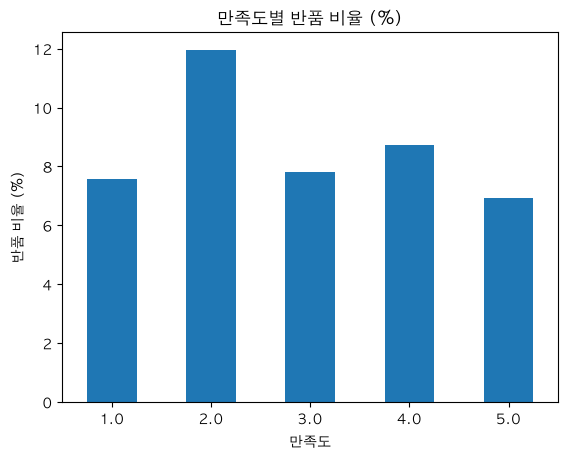

In [10]:
returned = (df["status"] == "반품")
rate = returned.groupby(df["satisfaction"]).mean() * 100
print(rate.round(1))

rate.plot.bar(title="만족도별 반품 비율 (%)", rot=0)
plt.xlabel("만족도")
plt.ylabel("반품 비율 (%)")
plt.show()

만족도가 낮을수록 반품이 많다고 보기는 어렵다. 점수 순서대로 반품 비율이 줄어들지 않는다.
2점이 12.0%로 가장 높고, 1점은 7.6%로 4점의 8.7%보다 낮다.

### 7. 카테고리 매출 1위의 이유는 무엇인가?

카테고리별 주문 건수, 매출 합계, 평균단가, 평균수량을 비교했다.

In [11]:
table = df.groupby("category").agg(
    건수=("total_sales", "size"),
    매출합_억=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
)
table["매출합_억"] = table["매출합_억"] / 1e8
table.sort_values("매출합_억", ascending=False).round(1)

,건수,매출합_억,평균단가,평균수량
category,,,,
가구,213,28.4,257322.9,51.0
식품,210,25.1,255232.9,47.3
전자제품,207,24.7,249651.6,48.0
도서,204,24.5,238500.6,49.5
의류,170,21.8,249447.2,51.6


매출 1위는 가구로 약 28.43억 원이다. 주문 213건, 평균단가 약 257,323원으로 두 항목 모두 가장 높다.
평균수량은 51.04개로 의류의 51.61개보다 낮다. 수량이 가장 많아서라기보다는 주문 건수와 단가가 모두 높은 점이 매출 1위에 기여한 것으로 보인다.